# Modèle 2 — Alerte précoce de surchauffe

**Projet PIC — Détection d'anomalies des batteries de véhicules électriques**
**Membre 3 — Mobio Ivan Junior** · Étape 6 du pipeline

---

## 1. Introduction

### 1.1 Contexte
Pendant une charge, la température de la batterie monte. Au-delà de **45 °C**, on parle de **surchauffe** : elle accélère le vieillissement des cellules et peut, dans les cas extrêmes, devenir dangereuse. Les seuils fixes ne détectent la surchauffe qu'**au moment où elle arrive**.

### 1.2 Problématique
> À partir des **15 premières minutes** d'une session de charge, peut-on **prédire** qu'elle finira en surchauffe, suffisamment tôt pour agir ?

### 1.3 Type de problème
| | |
|---|---|
| Apprentissage | **supervisé** |
| Tâche | **classification binaire** : 1 = la session finira > 45 °C, 0 = non |
| Particularité | classes **très déséquilibrées** (≈ 1 % de positifs) |
| Contrainte | n'utiliser **que** l'information disponible à la 15e minute |
| Métrique principale | **PR-AUC** pour comparer les modèles, **rappel** prioritaire pour la décision |

### 1.4 Démarche
| # | Étape |
|---|---|
| 2 | Importation des bibliothèques |
| 3 | Chargement des données |
| 4 | Analyse exploratoire (EDA) |
| 5 | Préparation des données |
| 6 | Séparation entraînement / test |
| 7 | Gestion du déséquilibre des classes |
| 8 | Métriques d'évaluation |
| 9 | Modèles de référence (baseline) |
| 10 | Random Forest |
| 11 | XGBoost |
| 12 | Validation croisée par véhicule |
| 13 | Optimisation des hyperparamètres |
| 14 | Sélection du modèle |
| 15 | Choix du seuil de décision |
| 16 | Évaluation finale sur le jeu de test |
| 17 | Analyse des erreurs |
| 18 | Interprétation du modèle |
| 19 | Évaluation métier : l'avance de l'alerte |
| 20 | Production des votes et sauvegarde |
| 21 | Conclusion et limites |

👉 Exécuter les cellules **dans l'ordre** (Maj + Entrée).

---
## 2. Importation des bibliothèques

| Bibliothèque | Rôle |
|---|---|
| `pandas`, `numpy` | manipulation des données |
| `matplotlib` | visualisation |
| `scikit-learn` | modèles (régression logistique, Random Forest), validation croisée, recherche d'hyperparamètres, métriques |
| `xgboost` | modèle XGBoost |

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

In [3]:
from sklearn.model_selection import GroupKFold, cross_val_predict, GridSearchCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
                             average_precision_score, roc_auc_score, confusion_matrix,
                             classification_report, precision_recall_curve, roc_curve)

Accès aux paramètres communs du projet (`src/config.py`) : chemins, seuil de 45 °C, véhicules de test.

In [4]:
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.config import SESSIONS_PARQUET, CLEAN_PARQUET, PROCESSED_DIR, FIGURES_DIR, TEST_VEHICLES, RANDOM_STATE, TEMP_ALERTE

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.precision", 3)
print("Seuil de surchauffe :", TEMP_ALERTE, "°C")
print("Véhicules de test   :", TEST_VEHICLES)
print("Graine aléatoire    :", RANDOM_STATE)

Seuil de surchauffe : 45 °C
Véhicules de test   : [17, 18, 19, 20]
Graine aléatoire    : 42


---
## 3. Chargement des données

Le fichier `sessions_features.parquet` est produit à l'étape 5 du pipeline (`src/sessions.py`). **Une ligne = une session de charge**, décrite par 22 variables.

In [5]:
sessions = pd.read_parquet(SESSIONS_PARQUET)
sessions.shape

(30855, 22)

In [6]:
sessions.head()

,vehicle_id,session_id,debut,fin,mois,nb_mesures,duree_min,soc_debut,soc_fin,courant_moyen,...,temp_max,vitesse_temp,ecart_v_moyen,ecart_v_max,temp_15min,vitesse_temp_15min,courant_moyen_15min,ecart_v_max_15min,soc_15min,session_longue
0,1,1,2019-07-26 20:02:35,2019-07-26 22:05:33,7,924,122.967,27.2,99.6,-47.191,...,44,0.024,0.020,0.025,42,0.067,-52.200,0.020,37.2,True
1,1,2,2019-07-27 04:06:56,2019-07-27 05:47:16,7,753,100.333,30.0,99.6,-56.375,...,43,0.040,0.024,0.030,41,0.134,-70.288,0.026,43.2,True
2,1,3,2019-07-28 17:25:00,2019-07-28 18:54:14,7,668,89.233,39.6,100.0,-54.775,...,40,0.056,0.024,0.030,37,0.134,-70.704,0.030,52.8,True
3,1,4,2019-07-29 11:31:06,2019-07-29 14:39:13,7,1377,188.117,26.8,86.4,-25.901,...,40,0.021,0.013,0.023,36,0.000,0.000,0.006,26.8,True
4,1,5,2019-07-29 22:20:45,2019-07-29 23:55:28,7,713,94.717,18.8,65.6,-39.084,...,37,0.032,0.016,0.022,34,0.000,-39.004,0.018,26.0,True


In [7]:
sessions.dtypes.to_frame("type")

,type
vehicle_id,int64
session_id,int64
debut,datetime64[ns]
fin,datetime64[ns]
mois,int32
nb_mesures,int64
duree_min,float64
soc_debut,float64
soc_fin,float64
courant_moyen,float64


In [8]:
print(f"{sessions.vehicle_id.nunique()} véhicules")
print(f"Période : du {sessions.debut.min():%d/%m/%Y} au {sessions.fin.max():%d/%m/%Y}")

20 véhicules
Période : du 22/07/2019 au 16/11/2021


---
## 4. Analyse exploratoire des données (EDA)

### 4.1 Valeurs manquantes

In [9]:
sessions.isna().sum().to_frame("valeurs manquantes").T

,vehicle_id,session_id,debut,fin,mois,nb_mesures,duree_min,soc_debut,soc_fin,courant_moyen,...,temp_max,vitesse_temp,ecart_v_moyen,ecart_v_max,temp_15min,vitesse_temp_15min,courant_moyen_15min,ecart_v_max_15min,soc_15min,session_longue
valeurs manquantes,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


**Résultat.** Aucune valeur manquante : pas d'imputation nécessaire.

### 4.2 Création de la variable cible

`label_surchauffe` = 1 si la température maximale de la session dépasse 45 °C.

In [10]:
sessions["label_surchauffe"] = (sessions["temp_max"] > TEMP_ALERTE).astype(int)
sessions["label_surchauffe"].value_counts().to_frame("sessions")

,sessions
label_surchauffe,
0,30552
1,303


### 4.3 Distribution de la variable cible

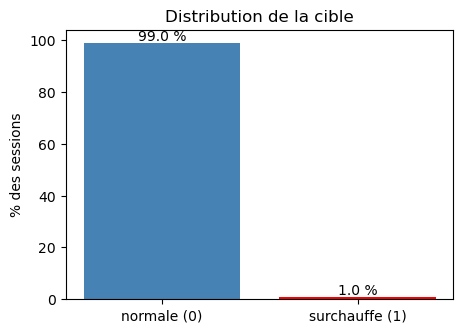

In [11]:
proportions = sessions["label_surchauffe"].value_counts(normalize=True)
plt.figure(figsize=(5, 3.5))
plt.bar(["normale (0)", "surchauffe (1)"], proportions.values * 100, color=["steelblue", "red"])
for i, v in enumerate(proportions.values * 100):
    plt.text(i, v + 1, f"{v:.1f} %", ha="center")
plt.ylabel("% des sessions"); plt.title("Distribution de la cible")
plt.show()

**Résultat.** Seulement **≈ 1 %** de sessions positives : le jeu de données est **fortement déséquilibré**. Ce point conditionne le choix des métriques (section 8) et de l'apprentissage (section 7).

### 4.4 Répartition des surchauffes par véhicule

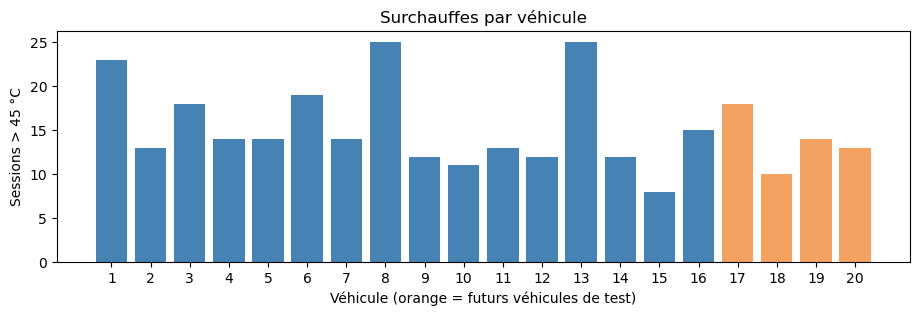

In [12]:
par_vehicule = sessions.groupby("vehicle_id")["label_surchauffe"].sum()
couleurs = ["#f4a261" if v in TEST_VEHICLES else "steelblue" for v in par_vehicule.index]
plt.figure(figsize=(11, 3))
plt.bar(par_vehicule.index, par_vehicule.values, color=couleurs)
plt.xticks(par_vehicule.index)
plt.xlabel("Véhicule (orange = futurs véhicules de test)"); plt.ylabel("Sessions > 45 °C")
plt.title("Surchauffes par véhicule")
plt.show()

**Résultat.** Tous les véhicules présentent des surchauffes (8 à 25 chacun). Le phénomène est **général** à la flotte : un modèle peut l'apprendre sur certains véhicules et le reconnaître sur d'autres.

### 4.5 Statistiques descriptives des variables disponibles à 15 minutes

In [13]:
variables_15 = ["temp_15min", "vitesse_temp_15min", "courant_moyen_15min", "ecart_v_max_15min",
                "soc_15min", "temp_debut", "soc_debut", "mois"]
sessions[variables_15].describe().T

,count,mean,std,min,25%,50%,75%,max
temp_15min,30855.0,32.785,5.550,12.000,29.000,33.000,37.000,47.000
vitesse_temp_15min,30855.0,0.080,0.068,0.000,0.067,0.067,0.134,0.803
courant_moyen_15min,30855.0,-60.132,13.548,-100.163,-70.105,-69.651,-47.885,0.000
ecart_v_max_15min,30855.0,0.034,0.009,0.006,0.028,0.033,0.040,0.098
soc_15min,30855.0,48.824,18.709,2.000,34.400,46.800,61.600,99.600
temp_debut,30855.0,31.607,5.861,9.000,28.000,32.000,36.000,47.000
soc_debut,30855.0,36.722,18.901,0.000,22.000,34.800,49.600,99.600
mois,30855.0,7.235,3.262,1.000,5.000,8.000,10.000,12.000


### 4.6 Comparaison des deux classes

Moyenne de chaque variable selon que la session finit ou non en surchauffe :

In [14]:
sessions.groupby("label_surchauffe")[variables_15].mean().T.rename(columns={0: "normale", 1: "surchauffe"})

label_surchauffe,normale,surchauffe
temp_15min,32.688,42.607
vitesse_temp_15min,0.080,0.056
courant_moyen_15min,-60.055,-67.927
ecart_v_max_15min,0.034,0.034
soc_15min,48.992,31.905
temp_debut,31.506,41.769
soc_debut,36.907,18.061
mois,7.232,7.584


**Résultat.** Les sessions qui finissent en surchauffe sont déjà **plus chaudes au départ et à 15 min** (≈ 42 °C contre 31-33 °C) et démarrent avec une **batterie plus vide** (SOC ≈ 17 % contre 36 %).

### 4.7 Distribution de chaque variable selon la classe

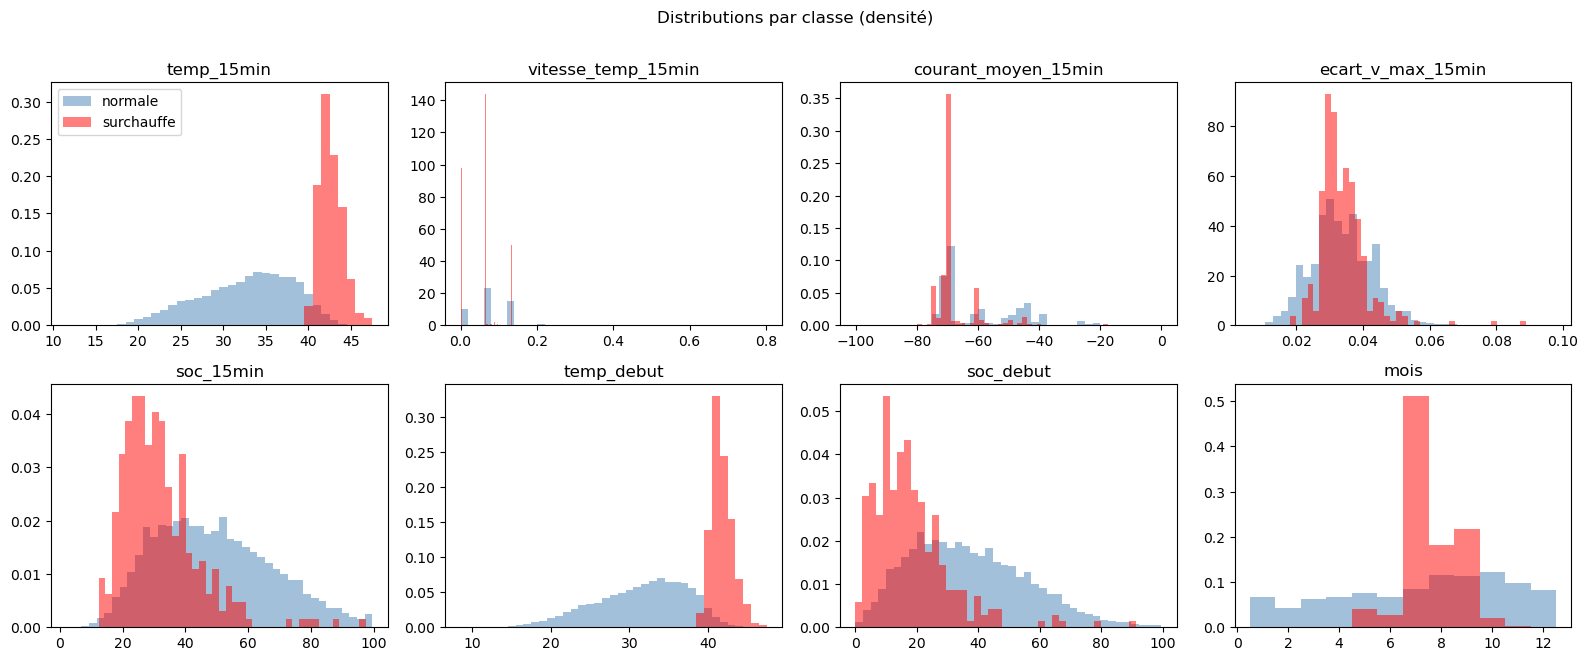

In [15]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
for ax, var in zip(axes.ravel(), variables_15):
    entiere = var in ("temp_15min", "temp_debut", "mois")      # valeurs entières : une barre par valeur
    bins = np.arange(sessions[var].min(), sessions[var].max() + 2) - 0.5 if entiere else 40
    for classe, couleur, nom in [(0, "steelblue", "normale"), (1, "red", "surchauffe")]:
        ax.hist(sessions.loc[sessions.label_surchauffe == classe, var], bins=bins, density=True,
                alpha=0.5, color=couleur, label=nom)
    ax.set_title(var)
axes[0, 0].legend()
plt.suptitle("Distributions par classe (densité)", y=1.01)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "alerte_distributions.png", dpi=120, bbox_inches="tight")
plt.show()

**Résultat.** `temp_15min`, `temp_debut` et `soc_debut` séparent nettement les deux classes ; `ecart_v_max_15min` et `mois` beaucoup moins. Les distributions se **chevauchent** : aucune variable seule ne suffit.

### 4.8 Corrélations entre variables

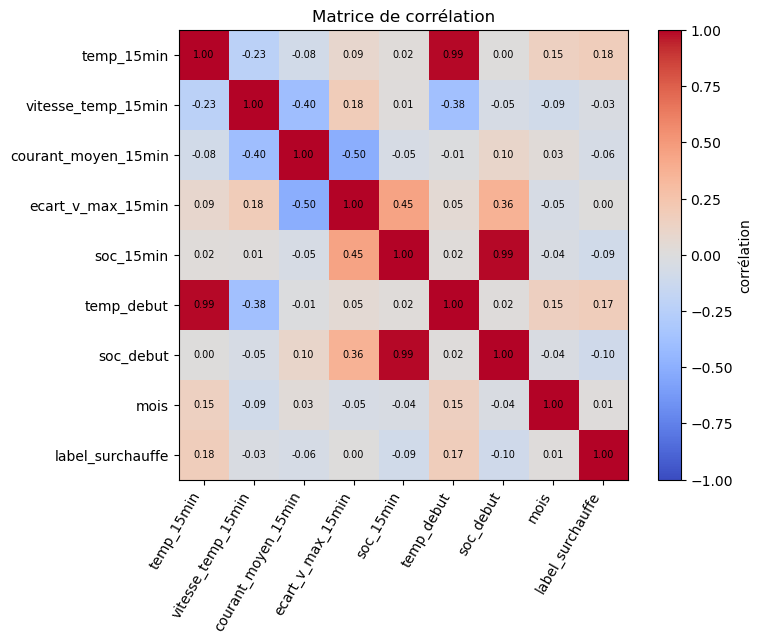

In [16]:
correlations = sessions[variables_15 + ["label_surchauffe"]].corr()
plt.figure(figsize=(8, 6.5))
plt.imshow(correlations, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="corrélation")
plt.xticks(range(len(correlations)), correlations.columns, rotation=60, ha="right")
plt.yticks(range(len(correlations)), correlations.columns)
for i in range(len(correlations)):
    for j in range(len(correlations)):
        plt.text(j, i, f"{correlations.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.title("Matrice de corrélation")
plt.tight_layout(); plt.show()

**Résultat.** Deux paires de variables sont **très corrélées** (≈ 0,99) : `temp_debut` / `temp_15min` et `soc_debut` / `soc_15min`. En 15 minutes, la température et le SOC bougent peu. Ce n'est pas bloquant pour la prédiction ; pour la régression logistique, on en tiendra compte à l'interprétation des coefficients (section 18). Aucune variable n'est corrélée à plus de 0,2 avec la cible : la relation n'est pas linéaire simple, d'où l'intérêt de combiner les variables.

---
## 5. Préparation des données

### 5.1 Définition de la population

Trois cas de figure :

| Cas | Traitement | Justification |
|---|---|---|
| Session de **moins de 15 min** | exclue (vote 0) | pas de fenêtre de 15 min à observer |
| **Déjà > 45 °C** à la 15e minute | exclue (vote 1 direct) | plus rien à anticiper |
| Les autres | **population du modèle** | une alerte précoce y a du sens |

In [17]:
longue = sessions["session_longue"].astype(bool)
deja_en_surchauffe = longue & (sessions["temp_15min"] > TEMP_ALERTE)
evaluable = longue & ~deja_en_surchauffe

pd.DataFrame({
    "sessions": [(~longue).sum(), deja_en_surchauffe.sum(), evaluable.sum()],
    "dont surchauffes": [sessions.loc[~longue, "label_surchauffe"].sum(),
                         sessions.loc[deja_en_surchauffe, "label_surchauffe"].sum(),
                         sessions.loc[evaluable, "label_surchauffe"].sum()],
}, index=["< 15 min", "déjà > 45 °C à 15 min", "population du modèle"])

,sessions,dont surchauffes
< 15 min,633,2
déjà > 45 °C à 15 min,6,6
population du modèle,30216,295


In [18]:
donnees = sessions[evaluable].copy()
print(f"Population : {len(donnees):,} sessions, {donnees.label_surchauffe.sum()} surchauffes "
      f"({donnees.label_surchauffe.mean():.2%})")

Population : 30,216 sessions, 295 surchauffes (0.98%)


### 5.2 Sélection des variables : éviter la fuite de données

**Fuite de données** (*data leakage*) : utiliser une information qui n'est pas disponible au moment de la prédiction. Ici, toute information **postérieure à la 15e minute** est interdite.

| Variable | Disponible à 15 min ? | Utilisée |
|---|---|---|
| `temp_15min`, `vitesse_temp_15min`, `courant_moyen_15min`, `ecart_v_max_15min`, `soc_15min` | ✅ | ✅ |
| `temp_debut`, `soc_debut`, `mois` | ✅ (dès le branchement) | ✅ |
| `temp_max`, `duree_min`, `soc_fin`, `courant_moyen`, `vitesse_temp`… | ❌ (fin de session) | ❌ |

In [19]:
FEATURES = ["temp_15min", "vitesse_temp_15min", "courant_moyen_15min", "ecart_v_max_15min",
            "soc_15min", "temp_debut", "soc_debut", "mois"]
CIBLE = "label_surchauffe"
print(len(FEATURES), "variables explicatives")

8 variables explicatives


### 5.3 Matrice X et vecteur y

In [20]:
X = donnees[FEATURES]
y = donnees[CIBLE]
groupes = donnees["vehicle_id"]
print("X :", X.shape, "| y :", y.shape)

X : (30216, 8) | y : (30216,)


### 5.4 Mise à l'échelle

La **régression logistique** est sensible à l'échelle des variables (le courant varie de −100 à 0, le mois de 1 à 12) : on la précède d'un `StandardScaler` (moyenne 0, écart-type 1). Les modèles à arbres (Random Forest, XGBoost) n'en ont pas besoin. Le scaler est placé **dans un `Pipeline`** : il est appris uniquement sur les données d'entraînement de chaque pli, sans fuite.

---
## 6. Séparation entraînement / test

**Séparation par véhicule** : 16 véhicules pour l'entraînement, **4 véhicules jamais vus** pour le test (17, 18, 19, 20). Une séparation aléatoire des sessions mélangerait les sessions d'un même véhicule entre les deux jeux et surestimerait les performances.

In [21]:
est_test = groupes.isin(TEST_VEHICLES)
X_train, y_train, g_train = X[~est_test], y[~est_test], groupes[~est_test]
X_test, y_test = X[est_test], y[est_test]

In [22]:
pd.DataFrame({
    "sessions": [len(y_train), len(y_test)],
    "surchauffes": [y_train.sum(), y_test.sum()],
    "taux de positifs": [f"{y_train.mean():.2%}", f"{y_test.mean():.2%}"],
    "véhicules": [g_train.nunique(), groupes[est_test].nunique()],
}, index=["entraînement", "test"])

,sessions,surchauffes,taux de positifs,véhicules
entraînement,24169,242,1.00%,16
test,6047,53,0.88%,4


In [23]:
assert not set(g_train) & set(TEST_VEHICLES)
print("Vérification : aucun véhicule commun entre entraînement et test")

Vérification : aucun véhicule commun entre entraînement et test


---
## 7. Gestion du déséquilibre des classes

### 7.1 Le paradoxe de l'exactitude
Un classifieur trivial qui prédit **toujours « normale »** :

In [24]:
prediction_triviale = np.zeros(len(y_test), dtype=int)
print(f"Exactitude (accuracy) : {accuracy_score(y_test, prediction_triviale):.1%}")
print(f"Rappel                : {recall_score(y_test, prediction_triviale):.0%}")

Exactitude (accuracy) : 99.1%
Rappel                : 0%


**99 % d'exactitude, 0 surchauffe détectée.** L'exactitude est donc **inutilisable** ici.

### 7.2 Pondération des classes
Plutôt que de dupliquer ou supprimer des données (sur/sous-échantillonnage), on **pondère** l'erreur : se tromper sur une surchauffe coûte autant que se tromper sur toutes les sessions normales réunies.

| Modèle | Paramètre |
|---|---|
| Régression logistique | `class_weight="balanced"` |
| Random Forest | `class_weight="balanced_subsample"` |
| XGBoost | `scale_pos_weight` = nb négatifs / nb positifs |

In [25]:
ratio = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight = {ratio:.1f} : une surchauffe pèse {ratio:.0f} fois plus qu'une session normale")

scale_pos_weight = 98.9 : une surchauffe pèse 99 fois plus qu'une session normale


---
## 8. Métriques d'évaluation

### 8.1 Matrice de confusion
| | Prédit 0 | Prédit 1 (alerte) |
|---|---|---|
| **Réel 0** | VN | FP (fausse alerte) |
| **Réel 1** | FN (surchauffe ratée) | VP |

### 8.2 Métriques
| Métrique | Formule | Interprétation |
|---|---|---|
| Rappel | VP / (VP + FN) | part des surchauffes détectées |
| Précision | VP / (VP + FP) | part des alertes justifiées |
| F1 | 2·P·R / (P + R) | équilibre précision / rappel |
| **F2** | 5·P·R / (4·P + R) | le rappel pèse **2 fois** plus |
| **PR-AUC** | aire sous la courbe précision-rappel | qualité globale, tous seuils, **adaptée au déséquilibre** (hasard ≈ 0,01) |
| ROC-AUC | aire sous la courbe ROC | qualité globale, mais **optimiste** en cas de fort déséquilibre |

### 8.3 Choix
- **Comparer les modèles** : PR-AUC en validation croisée.
- **Décider** (seuil d'alerte) : F2, car **rater une surchauffe est plus grave qu'une fausse alerte**.

In [26]:
def evaluer(y_vrai, proba, seuil):
    """Toutes les métriques pour des probabilités et un seuil de décision."""
    pred = (proba >= seuil).astype(int)
    vn, fp, fn, vp = confusion_matrix(y_vrai, pred, labels=[0, 1]).ravel()
    return {"rappel": recall_score(y_vrai, pred), "precision": precision_score(y_vrai, pred, zero_division=0),
            "f1": f1_score(y_vrai, pred), "f2": fbeta_score(y_vrai, pred, beta=2),
            "pr_auc": average_precision_score(y_vrai, proba), "roc_auc": roc_auc_score(y_vrai, proba),
            "VP": vp, "FN": fn, "FP": fp, "VN": vn}

---
## 9. Modèles de référence (baseline)

Un modèle complexe n'est justifié que s'il fait **mieux qu'une approche simple**. Deux références :
1. une **règle métier** : « alerte si `temp_15min` ≥ X °C » ;
2. une **régression logistique** : le modèle linéaire classique de classification.

### 9.1 Règle sur la température à 15 minutes
On choisit X sur l'entraînement (meilleur F2), puis on évalue sur le test.

In [27]:
def seuil_f2(y_vrai, score):
    """Seuil qui maximise le F2 sur la courbe précision-rappel."""
    p, r, s = precision_recall_curve(y_vrai, score)
    f2 = 5 * p * r / np.maximum(4 * p + r, 1e-12)
    return float(s[np.argmax(f2[:-1])])

seuil_regle = seuil_f2(y_train, X_train["temp_15min"])
print(f"Règle retenue : alerte si temp_15min ≥ {seuil_regle:.0f} °C")

Règle retenue : alerte si temp_15min ≥ 42 °C


In [28]:
res_regle = evaluer(y_test, X_test["temp_15min"], seuil_regle)
pd.Series(res_regle).round(3).to_frame("règle temp_15min (test)").T

,rappel,precision,f1,f2,pr_auc,roc_auc,VP,FN,FP,VN
règle temp_15min (test),0.717,0.216,0.332,0.49,0.269,0.982,38.0,15.0,138.0,5856.0


### 9.2 Régression logistique

Elle modélise la probabilité de surchauffe comme une fonction sigmoïde d'une combinaison linéaire des variables :

In [29]:
# P(surchauffe) = 1 / (1 + exp(-(b0 + b1·x1 + ... + b8·x8)))
logistique = Pipeline([
    ("scaler", StandardScaler()),
    ("modele", LogisticRegression(C=1.0, class_weight="balanced", max_iter=5000)),
])
logistique

Pipeline(steps=[('scaler', StandardScaler()),
                ('modele',
                 LogisticRegression(class_weight='balanced', max_iter=5000))])

Entraînement :

In [30]:
logistique.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('modele',
                 LogisticRegression(class_weight='balanced', max_iter=5000))])

Prédiction des probabilités sur le test, puis évaluation **au seuil par défaut de 0,5** (le seuil sera optimisé en section 15) :

In [31]:
proba_test_logistique = logistique.predict_proba(X_test)[:, 1]
pd.Series(evaluer(y_test, proba_test_logistique, 0.5)).round(3).to_frame("régression logistique, seuil 0,5 (test)").T

,rappel,precision,f1,f2,pr_auc,roc_auc,VP,FN,FP,VN
"régression logistique, seuil 0,5 (test)",0.981,0.38,0.547,0.745,0.817,0.998,52.0,1.0,85.0,5909.0


---
## 10. Random Forest

**Principe.** Un ensemble de 300 arbres de décision, chacun entraîné sur un échantillon bootstrap et un sous-ensemble aléatoire de variables. La probabilité finale est la moyenne des votes des arbres (*bagging*).

| Hyperparamètre | Valeur | Rôle |
|---|---|---|
| `n_estimators` | 300 | nombre d'arbres |
| `min_samples_leaf` | 5 | au moins 5 sessions par feuille (limite le surapprentissage) |
| `class_weight` | `balanced_subsample` | pondération des classes dans chaque échantillon bootstrap |

In [32]:
foret = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced_subsample",
                               n_jobs=-1, random_state=RANDOM_STATE)
foret.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced_subsample', min_samples_leaf=5,
                       n_estimators=300, n_jobs=-1, random_state=42)

In [33]:
proba_test_foret = foret.predict_proba(X_test)[:, 1]
pd.Series(evaluer(y_test, proba_test_foret, 0.5)).round(3).to_frame("Random Forest, seuil 0,5 (test)").T

,rappel,precision,f1,f2,pr_auc,roc_auc,VP,FN,FP,VN
"Random Forest, seuil 0,5 (test)",0.887,0.644,0.746,0.825,0.849,0.998,47.0,6.0,26.0,5968.0


---
## 11. XGBoost

**Principe.** *Gradient boosting* : les arbres sont construits **séquentiellement**, chacun corrigeant les erreurs résiduelles des précédents. Le `learning_rate` limite la contribution de chaque arbre.

Hyperparamètres de départ (ils seront optimisés en section 13) :

In [34]:
xgb_initial = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
                            scale_pos_weight=ratio, eval_metric="aucpr", n_jobs=-1, random_state=RANDOM_STATE)
xgb_initial.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='aucpr', feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.05, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=4,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=300,
              n_jobs=-1, num_parallel_tree=None, ...)

In [35]:
proba_test_xgb_initial = xgb_initial.predict_proba(X_test)[:, 1]
pd.Series(evaluer(y_test, proba_test_xgb_initial, 0.5)).round(3).to_frame("XGBoost initial, seuil 0,5 (test)").T

,rappel,precision,f1,f2,pr_auc,roc_auc,VP,FN,FP,VN
"XGBoost initial, seuil 0,5 (test)",0.868,0.648,0.742,0.813,0.88,0.998,46.0,7.0,25.0,5969.0


⚠️ Ces premiers résultats sur le test sont donnés **à titre indicatif**. On ne choisit **jamais** un modèle d'après le test : sinon le test ne mesure plus la performance sur des données nouvelles. Le choix se fait par **validation croisée** (sections 12 à 14).

---
## 12. Validation croisée par véhicule

**`GroupKFold` (4 plis)** : les 16 véhicules d'entraînement sont répartis en 4 groupes ; à chaque pli, on entraîne sur 12 véhicules et on évalue sur les 4 autres. Un véhicule n'est jamais à la fois dans l'entraînement et la validation d'un même pli.

In [36]:
plis = GroupKFold(n_splits=4)
for i, (idx_entr, idx_val) in enumerate(plis.split(X_train, y_train, g_train), 1):
    print(f"Pli {i} : validation sur les véhicules {sorted(int(v) for v in g_train.iloc[idx_val].unique())}, "
          f"{y_train.iloc[idx_val].sum()} surchauffes")

Pli 1 : validation sur les véhicules [2, 8, 13, 14], 74 surchauffes
Pli 2 : validation sur les véhicules [1, 3, 9, 12], 63 surchauffes
Pli 3 : validation sur les véhicules [4, 6, 7, 10], 57 surchauffes
Pli 4 : validation sur les véhicules [5, 11, 15, 16], 48 surchauffes


On évalue chaque modèle pli par pli (PR-AUC) :

In [37]:
def pr_auc_par_pli(modele):
    scores = []
    for idx_entr, idx_val in plis.split(X_train, y_train, g_train):
        modele.fit(X_train.iloc[idx_entr], y_train.iloc[idx_entr])
        proba = modele.predict_proba(X_train.iloc[idx_val])[:, 1]
        scores.append(average_precision_score(y_train.iloc[idx_val], proba))
    return np.array(scores)

scores_cv = {
    "régression logistique": pr_auc_par_pli(logistique),
    "Random Forest": pr_auc_par_pli(foret),
    "XGBoost initial": pr_auc_par_pli(xgb_initial),
}
pd.DataFrame(scores_cv, index=[f"pli {i}" for i in range(1, 5)]).T.assign(
    moyenne=lambda d: d.mean(axis=1), ecart_type=lambda d: d.iloc[:, :4].std(axis=1)).round(3)

,pli 1,pli 2,pli 3,pli 4,moyenne,ecart_type
régression logistique,0.868,0.856,0.782,0.836,0.835,0.038
Random Forest,0.819,0.743,0.810,0.791,0.791,0.034
XGBoost initial,0.849,0.817,0.762,0.813,0.810,0.036


C:\Users\hp\AppData\Local\Temp\ipykernel_30676\2443401919.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(scores_cv.values(), labels=scores_cv.keys())


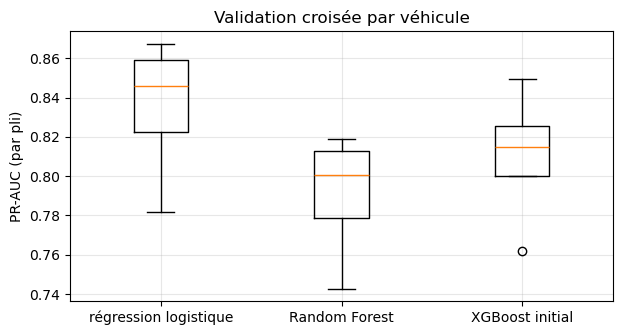

In [38]:
plt.figure(figsize=(7, 3.5))
plt.boxplot(scores_cv.values(), labels=scores_cv.keys())
plt.ylabel("PR-AUC (par pli)"); plt.title("Validation croisée par véhicule")
plt.grid(alpha=0.3); plt.show()

**Résultat.** La régression logistique obtient la meilleure PR-AUC moyenne. Les écarts entre modèles restent **du même ordre que la variabilité entre plis** (≈ ± 0,03).

---
## 13. Optimisation des hyperparamètres

Recherche en grille (`GridSearchCV`) avec la **même validation croisée par véhicule** et la PR-AUC comme critère.

### 13.1 XGBoost : profondeur des arbres et nombre d'arbres

In [39]:
grille_xgb = GridSearchCV(
    XGBClassifier(learning_rate=0.05, subsample=0.8, scale_pos_weight=ratio, eval_metric="aucpr",
                  n_jobs=-1, random_state=RANDOM_STATE),
    param_grid={"max_depth": [3, 4, 5, 6], "n_estimators": [200, 300, 500]},
    scoring="average_precision", cv=plis)
grille_xgb.fit(X_train, y_train, groups=g_train)
print("Meilleurs hyperparamètres :", grille_xgb.best_params_, f"| PR-AUC = {grille_xgb.best_score_:.3f}")

Meilleurs hyperparamètres : {'max_depth': 3, 'n_estimators': 200} | PR-AUC = 0.819


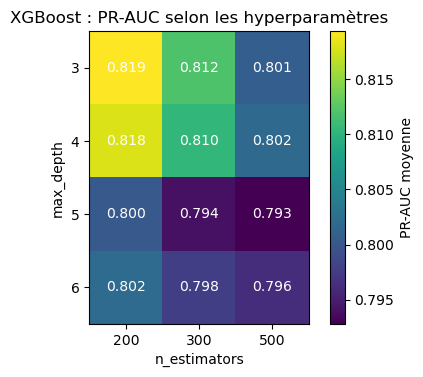

In [40]:
tableau = pd.DataFrame(grille_xgb.cv_results_).pivot(index="param_max_depth", columns="param_n_estimators",
                                                     values="mean_test_score")
plt.figure(figsize=(5.5, 3.8))
plt.imshow(tableau, cmap="viridis")
plt.colorbar(label="PR-AUC moyenne")
plt.xticks(range(tableau.shape[1]), tableau.columns); plt.yticks(range(tableau.shape[0]), tableau.index)
for i in range(tableau.shape[0]):
    for j in range(tableau.shape[1]):
        plt.text(j, i, f"{tableau.iloc[i, j]:.3f}", ha="center", va="center", color="white")
plt.xlabel("n_estimators"); plt.ylabel("max_depth"); plt.title("XGBoost : PR-AUC selon les hyperparamètres")
plt.show()

**Résultat.** Les arbres **peu profonds** (3-4 niveaux) et **moins nombreux** donnent les meilleurs résultats : avec seulement 242 surchauffes à l'entraînement, un modèle plus complexe sur-apprend.

### 13.2 Régression logistique : force de régularisation C
Un C petit = forte régularisation (coefficients contraints) ; un C grand = faible régularisation.

In [41]:
grille_logistique = GridSearchCV(logistique, param_grid={"modele__C": [0.001, 0.01, 0.1, 1, 10, 100]},
                                 scoring="average_precision", cv=plis)
grille_logistique.fit(X_train, y_train, groups=g_train)
pd.DataFrame(grille_logistique.cv_results_)[["param_modele__C", "mean_test_score", "std_test_score"]].round(3)

,param_modele__C,mean_test_score,std_test_score
0,0.001,0.749,0.035
1,0.010,0.820,0.026
2,0.100,0.834,0.029
3,1.000,0.835,0.033
4,10.000,0.834,0.033
5,100.000,0.834,0.033


**Résultat.** Au-delà de C = 0,1, la performance plafonne (≈ 0,835) : la valeur par défaut **C = 1** est retenue.

---
## 14. Sélection du modèle

On compare les modèles **optimisés** sur les probabilités hors-échantillon de la validation croisée (chaque session du train est prédite par un modèle qui n'a pas vu son véhicule).

In [42]:
candidats = {
    "régression logistique": grille_logistique.best_estimator_,
    "Random Forest": foret,
    "XGBoost optimisé": grille_xgb.best_estimator_,
}
proba_oof = {nom: cross_val_predict(m, X_train, y_train, groups=g_train, cv=plis, method="predict_proba")[:, 1]
             for nom, m in candidats.items()}
proba_oof["règle temp_15min"] = X_train["temp_15min"].to_numpy()

selection = pd.DataFrame({nom: {"PR-AUC (cv)": average_precision_score(y_train, p),
                                "ROC-AUC (cv)": roc_auc_score(y_train, p)} for nom, p in proba_oof.items()}).T
selection.sort_values("PR-AUC (cv)", ascending=False).round(3)

,PR-AUC (cv),ROC-AUC (cv)
régression logistique,0.833,0.998
XGBoost optimisé,0.818,0.998
Random Forest,0.779,0.997
règle temp_15min,0.300,0.985


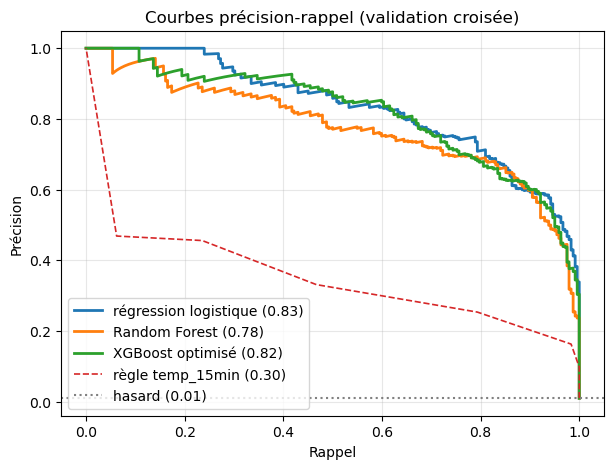

In [43]:
plt.figure(figsize=(7, 5))
for nom, p in proba_oof.items():
    prec, rap, _ = precision_recall_curve(y_train, p)
    plt.plot(rap, prec, lw=2 if nom != "règle temp_15min" else 1.2, ls="--" if nom == "règle temp_15min" else "-",
             label=f"{nom} ({average_precision_score(y_train, p):.2f})")
plt.axhline(y_train.mean(), color="grey", ls=":", label=f"hasard ({y_train.mean():.2f})")
plt.xlabel("Rappel"); plt.ylabel("Précision"); plt.title("Courbes précision-rappel (validation croisée)")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig(FIGURES_DIR / "alerte_courbes_pr.png", dpi=120, bbox_inches="tight")
plt.show()

In [44]:
nom_retenu = selection.drop(index="règle temp_15min")["PR-AUC (cv)"].idxmax()
modele_retenu = candidats[nom_retenu]
print("Modèle retenu :", nom_retenu)

Modèle retenu : régression logistique


**Décision : la régression logistique.**
- C'est le modèle qui a la **meilleure PR-AUC en validation croisée** ;
- à performance comparable, on préfère le **modèle le plus simple** (principe de parcimonie) ;
- il est **interprétable** : ses coefficients se lisent directement (section 18).

Les trois modèles font **très nettement mieux que la règle simple** (PR-AUC ≈ 0,8 contre 0,3) : le machine learning apporte un gain réel.

---
## 15. Choix du seuil de décision

Le modèle donne une probabilité ; il faut un **seuil** pour décider d'alerter. Avec la pondération des classes, les probabilités sont décalées vers le haut : le seuil de 0,5 n'a pas de raison d'être optimal. On choisit le seuil qui **maximise le F2** sur les probabilités hors-échantillon du train.

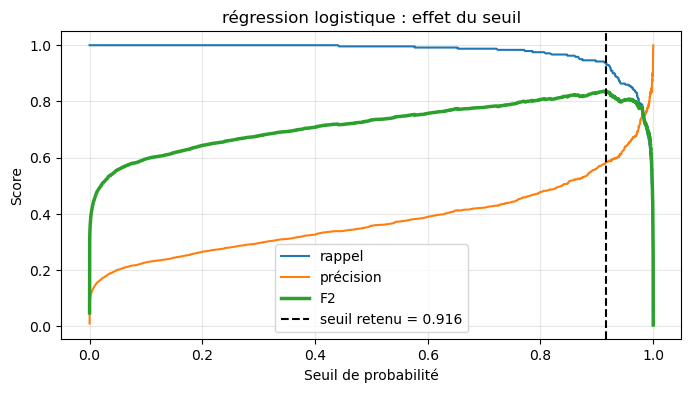

Alerte si P(surchauffe) ≥ 0.916


In [45]:
p, r, s = precision_recall_curve(y_train, proba_oof[nom_retenu])
f2 = 5 * p * r / np.maximum(4 * p + r, 1e-12)
seuil = seuil_f2(y_train, proba_oof[nom_retenu])

plt.figure(figsize=(8, 4))
plt.plot(s, r[:-1], label="rappel"); plt.plot(s, p[:-1], label="précision"); plt.plot(s, f2[:-1], lw=2.5, label="F2")
plt.axvline(seuil, color="k", ls="--", label=f"seuil retenu = {seuil:.3f}")
plt.xlabel("Seuil de probabilité"); plt.ylabel("Score"); plt.title(f"{nom_retenu} : effet du seuil")
plt.legend(); plt.grid(alpha=0.3); plt.show()
print(f"Alerte si P(surchauffe) ≥ {seuil:.3f}")

---
## 16. Évaluation finale sur le jeu de test

Le modèle retenu est réentraîné sur **tout** le jeu d'entraînement, puis évalué **une seule fois** sur les 4 véhicules de test. Les autres modèles sont donnés pour comparaison, chacun avec son propre seuil (choisi de la même manière).

In [46]:
modele_retenu.fit(X_train, y_train)
proba_test = modele_retenu.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= seuil).astype(int)

In [47]:
print(classification_report(y_test, pred_test, target_names=["normale", "surchauffe"], digits=3))

              precision    recall  f1-score   support

     normale      0.999     0.995     0.997      5994
  surchauffe      0.613     0.868     0.719        53

    accuracy                          0.994      6047
   macro avg      0.806     0.932     0.858      6047
weighted avg      0.995     0.994     0.995      6047



In [48]:
comparaison = {"règle temp_15min": evaluer(y_test, X_test["temp_15min"], seuil_regle)}
for nom, m in candidats.items():
    m.fit(X_train, y_train)
    comparaison[nom] = evaluer(y_test, m.predict_proba(X_test)[:, 1], seuil_f2(y_train, proba_oof[nom]))
pd.DataFrame(comparaison).T[["rappel", "precision", "f1", "f2", "pr_auc", "roc_auc", "VP", "FN", "FP"]].round(3)

,rappel,precision,f1,f2,pr_auc,roc_auc,VP,FN,FP
règle temp_15min,0.717,0.216,0.332,0.490,0.269,0.982,38.0,15.0,138.0
régression logistique,0.868,0.613,0.719,0.801,0.817,0.998,46.0,7.0,29.0
Random Forest,0.887,0.635,0.740,0.822,0.849,0.998,47.0,6.0,27.0
XGBoost optimisé,0.887,0.610,0.723,0.813,0.863,0.998,47.0,6.0,30.0


### 16.1 Matrices de confusion

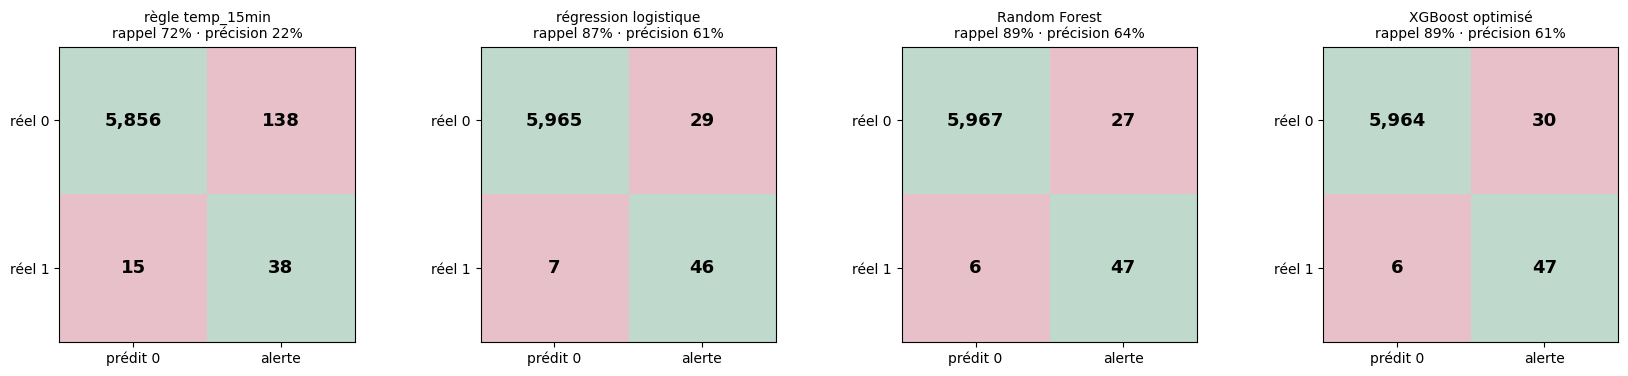

In [49]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, (nom, r) in zip(axes, comparaison.items()):
    mat = np.array([[r["VN"], r["FP"]], [r["FN"], r["VP"]]]).astype(int)
    ax.imshow([[0, 1], [1, 0]], cmap="RdYlGn_r", alpha=0.25)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{mat[i, j]:,}", ha="center", va="center", fontsize=13, weight="bold")
    ax.set_xticks([0, 1], ["prédit 0", "alerte"]); ax.set_yticks([0, 1], ["réel 0", "réel 1"])
    ax.set_title(f"{nom}\nrappel {r['rappel']:.0%} · précision {r['precision']:.0%}", fontsize=10)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "alerte_matrices_confusion.png", dpi=120, bbox_inches="tight")
plt.show()

### 16.2 Courbes ROC et précision-rappel du modèle retenu (test)

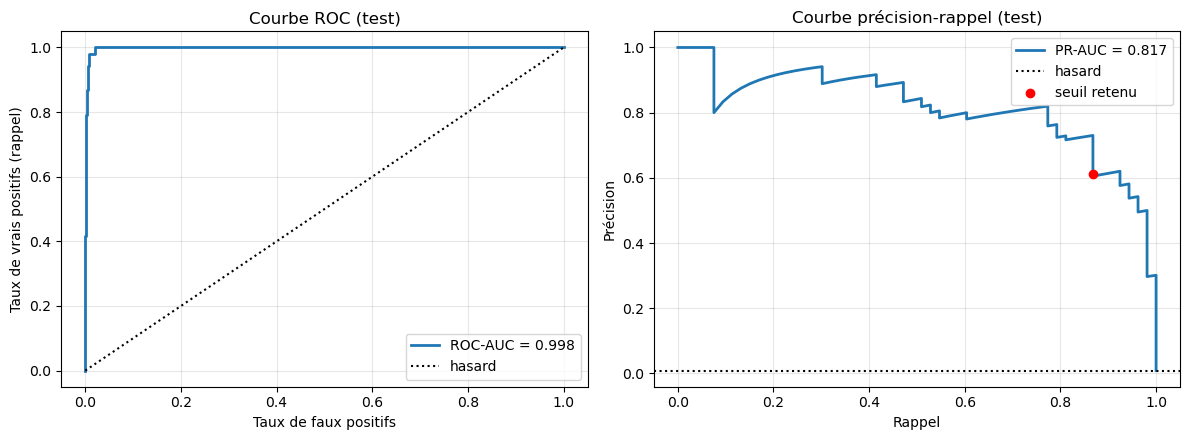

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
fpr, tpr, _ = roc_curve(y_test, proba_test)
axes[0].plot(fpr, tpr, lw=2, label=f"ROC-AUC = {roc_auc_score(y_test, proba_test):.3f}")
axes[0].plot([0, 1], [0, 1], "k:", label="hasard")
axes[0].set_xlabel("Taux de faux positifs"); axes[0].set_ylabel("Taux de vrais positifs (rappel)")
axes[0].set_title("Courbe ROC (test)"); axes[0].legend()
prec, rap, _ = precision_recall_curve(y_test, proba_test)
axes[1].plot(rap, prec, lw=2, label=f"PR-AUC = {average_precision_score(y_test, proba_test):.3f}")
axes[1].axhline(y_test.mean(), color="k", ls=":", label="hasard")
axes[1].scatter(recall_score(y_test, pred_test), precision_score(y_test, pred_test), color="red", zorder=3,
                label="seuil retenu")
axes[1].set_xlabel("Rappel"); axes[1].set_ylabel("Précision"); axes[1].set_title("Courbe précision-rappel (test)")
axes[1].legend()
for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Résultat.**
- Le modèle retenu détecte **46 surchauffes sur 53** (rappel ≈ 87 %) avec ≈ 61 % d'alertes justifiées, contre 38 / 53 et 22 % pour la règle simple.
- Le ROC-AUC est très élevé (≈ 1,0) mais **trompeur** en cas de déséquilibre : la PR-AUC (≈ 0,82) est la mesure à retenir.
- Sur le test, XGBoost et Random Forest font légèrement mieux que la régression logistique (49 et 47 détections). Avec **53 surchauffes seulement** dans le test, ces écarts (1 à 3 sessions) sont **dans la marge d'incertitude** ; le choix fait par validation croisée, qui repose sur 242 surchauffes, reste le plus fiable. Changer de modèle maintenant serait choisir **sur le test**.

---
## 17. Analyse des erreurs

### 17.1 Les surchauffes ratées (faux négatifs)

In [51]:
analyse = X_test.assign(reel=y_test.values, proba=proba_test, prediction=pred_test,
                        temp_max=donnees.loc[X_test.index, "temp_max"], vehicule=groupes[est_test])
analyse[(analyse.reel == 1) & (analyse.prediction == 0)][
    ["vehicule", "temp_debut", "temp_15min", "soc_debut", "courant_moyen_15min", "temp_max", "proba"]].round(3)

,vehicule,temp_debut,temp_15min,soc_debut,courant_moyen_15min,temp_max,proba
26007,17,39,40,18.8,-69.955,46,0.313
27809,19,40,41,18.0,-70.518,46,0.915
29071,19,40,41,20.8,-72.257,46,0.774
29183,19,39,40,6.4,-70.147,46,0.914
29365,20,39,40,11.2,-73.566,46,0.878
29875,20,40,41,14.4,-70.932,46,0.916
29890,20,41,42,14.0,-44.972,46,0.824


**Interprétation.** Les 7 surchauffes ratées sont des cas **limites** : toutes finissent à **46 °C**, juste au-dessus du seuil, en partant de 39-41 °C. Pour 5 d'entre elles, la probabilité (0,77 à 0,915) est **juste sous le seuil** de 0,916 : le modèle les jugeait déjà à risque.

### 17.2 Les fausses alertes (faux positifs)

In [52]:
fausses_alertes = analyse[(analyse.reel == 0) & (analyse.prediction == 1)]
print(f"{len(fausses_alertes)} fausses alertes ; température maximale atteinte :")
fausses_alertes["temp_max"].value_counts().sort_index().to_frame("sessions").T

29 fausses alertes ; température maximale atteinte :


temp_max,41,44,45
sessions,1,4,24


**Interprétation.** 24 fausses alertes sur 29 concernent des sessions qui ont fini **exactement à 45 °C** (le seuil est « strictement supérieur à 45 »), et 4 à 44 °C. Ce sont des **« presque surchauffes »**, pas des erreurs grossières : le capteur mesurant au degré près, ces sessions étaient à 1 °C de l'étiquette positive.

---
## 18. Interprétation du modèle

### 18.1 Coefficients de la régression logistique
Les variables étant standardisées, chaque coefficient mesure l'effet d'**un écart-type** de la variable sur le logarithme de la cote (*log-odds*) de surchauffe. Positif = augmente le risque.

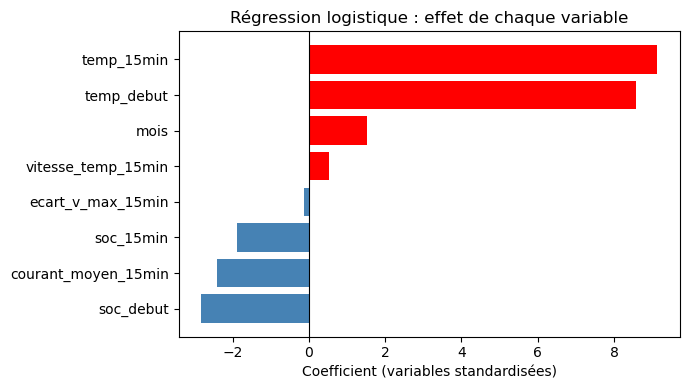

,coefficient
soc_debut,-2.816
courant_moyen_15min,-2.405
soc_15min,-1.894
ecart_v_max_15min,-0.125
vitesse_temp_15min,0.531
mois,1.528
temp_debut,8.583
temp_15min,9.129


In [53]:
coefficients = pd.Series(modele_retenu.named_steps["modele"].coef_[0], index=FEATURES).sort_values()
plt.figure(figsize=(7, 4))
plt.barh(coefficients.index, coefficients.values, color=["red" if c > 0 else "steelblue" for c in coefficients])
plt.axvline(0, color="k", lw=0.8)
plt.xlabel("Coefficient (variables standardisées)"); plt.title("Régression logistique : effet de chaque variable")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "alerte_coefficients.png", dpi=120, bbox_inches="tight")
plt.show()
coefficients.round(3).to_frame("coefficient")

**Interprétation.**
- **`temp_15min` (+9,1) et `temp_debut` (+8,6)** : les coefficients les plus forts, tous deux positifs. Une batterie **déjà chaude** a peu de marge avant 45 °C. Ces deux variables étant corrélées à 0,99 (section 4.8), leurs poids respectifs sont instables : il faut les lire **ensemble**.
- **`soc_debut` (−2,8) et `soc_15min` (−1,9)** : négatifs. Un **SOC bas** augmente le risque, car la charge sera longue.
- **`courant_moyen_15min` (−2,4)** : négatif. Le courant de charge est **négatif** ; plus il est négatif (charge plus forte), plus le risque augmente.
- **`mois` (+1,5)** : effet saisonnier. Les surchauffes se concentrent de juillet à septembre (5,6 % des sessions en juillet, 0 % de novembre à avril).
- `vitesse_temp_15min` et `ecart_v_max_15min` : effet faible.

### 18.2 Importance par permutation (sur le test)
Méthode indépendante du modèle : on **mélange** une variable et on mesure la perte de PR-AUC. Plus la perte est grande, plus la variable est utile. Elle n'est pas faussée par la corrélation des coefficients.

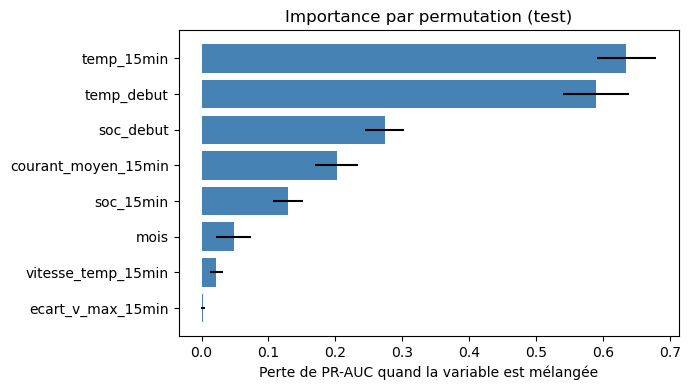

In [54]:
permutation = permutation_importance(modele_retenu, X_test, y_test, scoring="average_precision",
                                     n_repeats=20, random_state=RANDOM_STATE)
importance = pd.Series(permutation.importances_mean, index=FEATURES).sort_values()
plt.figure(figsize=(7, 4))
plt.barh(importance.index, importance.values, xerr=pd.Series(permutation.importances_std, index=FEATURES)[importance.index],
         color="steelblue")
plt.xlabel("Perte de PR-AUC quand la variable est mélangée"); plt.title("Importance par permutation (test)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "alerte_importance.png", dpi=120, bbox_inches="tight")
plt.show()

**Interprétation.** Les deux **températures** (à 15 min et au départ) sont décisives, suivies du **SOC de départ** et du **courant** : une batterie **déjà chaude**, **presque vide** et **chargée fort** est la situation à risque. L'écart de tension entre cellules n'apporte rien à la prédiction de surchauffe.

---
## 19. Évaluation métier : l'avance de l'alerte

Une alerte précoce n'a de valeur que si elle arrive **avant** la surchauffe. On relit les mesures brutes nettoyées (16 millions de lignes) pour trouver la **première minute où la batterie dépasse 45 °C** dans chaque session détectée.

⏳ Environ 1 minute.

In [55]:
from src.sessions import ajouter_session_id

mesures = pd.read_parquet(CLEAN_PARQUET, columns=["vehicle_id", "time", "temp_max"])
mesures = ajouter_session_id(mesures)            # mêmes identifiants de session que l'étape 5
premiere_45 = mesures[mesures.temp_max > TEMP_ALERTE].groupby("session_id")["time"].min()
del mesures

In [56]:
detectees = donnees.loc[X_test.index][(y_test == 1).to_numpy() & (pred_test == 1)]
minutes_45 = (premiere_45.reindex(detectees.session_id).to_numpy() - detectees.debut.to_numpy()) / np.timedelta64(1, "m")
avance = minutes_45 - 15                         # l'alerte tombe à la 15e minute
print(f"{len(detectees)} surchauffes détectées")
print(f"Avance : médiane {np.median(avance):.0f} min, moyenne {avance.mean():.0f} min, minimum {avance.min():.0f} min")

46 surchauffes détectées
Avance : médiane 32 min, moyenne 36 min, minimum 5 min


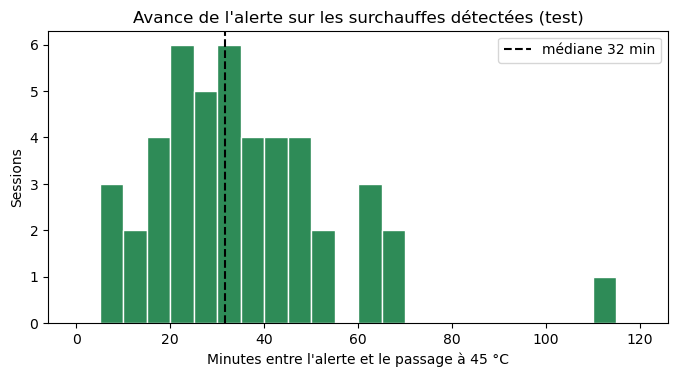

In [57]:
plt.figure(figsize=(8, 3.8))
plt.hist(avance, bins=range(0, int(avance.max()) + 10, 5), color="seagreen", edgecolor="white")
plt.axvline(np.median(avance), color="k", ls="--", label=f"médiane {np.median(avance):.0f} min")
plt.xlabel("Minutes entre l'alerte et le passage à 45 °C"); plt.ylabel("Sessions")
plt.title("Avance de l'alerte sur les surchauffes détectées (test)")
plt.legend()
plt.savefig(FIGURES_DIR / "alerte_avance.png", dpi=120, bbox_inches="tight")
plt.show()

**Exemple** : courbe de température d'une session de test détectée (avance proche de la médiane).

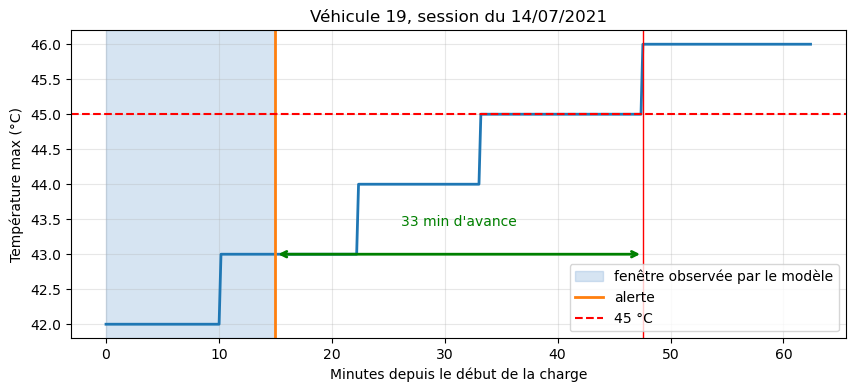

In [58]:
ex = detectees.assign(avance=avance).sort_values("avance").iloc[len(detectees) // 2]
courbe = pd.read_parquet(CLEAN_PARQUET, columns=["vehicle_id", "time", "temp_max"],
                         filters=[("vehicle_id", "==", int(ex.vehicle_id))])
courbe = courbe[(courbe.time >= ex.debut) & (courbe.time <= ex.fin)]
minutes = (courbe.time - ex.debut).dt.total_seconds() / 60

plt.figure(figsize=(10, 4))
plt.plot(minutes, courbe.temp_max, lw=2)
plt.axvspan(0, 15, color="#7aa6d6", alpha=0.3, label="fenêtre observée par le modèle")
plt.axvline(15, color="tab:orange", lw=2, label="alerte")
plt.axhline(TEMP_ALERTE, color="red", ls="--", label="45 °C")
plt.axvline(15 + ex.avance, color="red", lw=1)
plt.annotate("", xy=(15 + ex.avance, TEMP_ALERTE - 2), xytext=(15, TEMP_ALERTE - 2),
             arrowprops=dict(arrowstyle="<->", color="green", lw=2))
plt.text(15 + ex.avance / 2, TEMP_ALERTE - 1.6, f"{ex.avance:.0f} min d'avance", ha="center", color="green")
plt.xlabel("Minutes depuis le début de la charge"); plt.ylabel("Température max (°C)")
plt.title(f"Véhicule {int(ex.vehicle_id)}, session du {ex.debut:%d/%m/%Y}")
plt.legend(loc="lower right"); plt.grid(alpha=0.3)
plt.savefig(FIGURES_DIR / "alerte_exemple_session.png", dpi=120, bbox_inches="tight")
plt.show()

---
## 20. Production des votes et sauvegarde

Le modèle vote pour **toutes** les sessions (contrat `TACHE.md`), puis les votes sont enregistrés pour la fusion.

In [59]:
votes = sessions[["vehicle_id", "session_id"]].copy()
votes["proba_alerte_precoce"] = np.nan
votes.loc[evaluable, "proba_alerte_precoce"] = modele_retenu.predict_proba(sessions.loc[evaluable, FEATURES])[:, 1]
votes["vote_alerte_precoce_surchauffe"] = ((votes["proba_alerte_precoce"] >= seuil) | deja_en_surchauffe).astype(int)
votes["ap_evaluable"] = evaluable | deja_en_surchauffe
votes["raison_alerte_precoce"] = np.select(
    [deja_en_surchauffe, votes["vote_alerte_precoce_surchauffe"].eq(1), ~(evaluable | deja_en_surchauffe)],
    ["déjà > 45 °C à 15 min", "risque de surchauffe prévu", "session < 15 min"], default="")
votes["raison_alerte_precoce"].value_counts()

raison_alerte_precoce
                              29748
session < 15 min                633
risque de surchauffe prévu      468
déjà > 45 °C à 15 min             6
Name: count, dtype: int64

In [60]:
chemin = PROCESSED_DIR / "votes_alerte_precoce.parquet"
votes.to_parquet(chemin, index=False)
print("Votes enregistrés :", chemin, votes.shape)

Votes enregistrés : C:\Users\hp\Documents\HESTIM 2\PROJET PISTE\battery-charging-data-of-on-road-electric-vehicles-main\Dataset_automobile\data\processed\votes_alerte_precoce.parquet (30855, 6)


Le modèle final est enregistré dans **MLflow** (`src/mlops.py`) en lançant `python -m src.models.alerte_precoce`, qui reproduit exactement ce notebook (mêmes données, hyperparamètres et seuil).

---
## 21. Conclusion et limites

### 21.1 Synthèse
| | Règle `temp_15min` ≥ 42 °C | **Régression logistique (retenue)** |
|---|---|---|
| PR-AUC (validation croisée) | 0,30 | **0,83** |
| Surchauffes détectées (test) | 38 / 53 (72 %) | **46 / 53 (87 %)** |
| Précision (test) | 22 % | **61 %** |
| Fausses alertes (≈ 6 000 sessions de test) | 138 | **29** |
| Avance médiane | — | **≈ 32 min** avant 45 °C |

**Réponse à la problématique :** oui, les 15 premières minutes suffisent à prédire environ 9 surchauffes sur 10, avec une demi-heure d'avance en général. Les facteurs de risque sont une batterie **déjà chaude** et **presque vide** au branchement.

### 21.2 Démarche
- Séparation **par véhicule** et validation croisée **par véhicule** : performances mesurées sur des véhicules jamais vus.
- Aucune **fuite de données** : seules les informations connues à la 15e minute sont utilisées.
- Choix du modèle et des hyperparamètres **par validation croisée**, jamais sur le test.
- Modèle le plus **simple et interprétable** retenu à performance égale.

### 21.3 Limites
- L'étiquette est **dérivée du seuil de 45 °C** : le modèle prédit un dépassement de seuil, pas une panne confirmée.
- **53 surchauffes** seulement dans le test : les métriques ont une incertitude de quelques points.
- Le seuil F2 privilégie le rappel : ≈ 4 alertes sur 10 sont des « presque surchauffes » (44-45 °C).
- Surchauffe uniquement : pas de modèle 2 pour la cellule (option D, 90 % des cas sur le véhicule 9).

### 21.4 Perspectives
- Fenêtres plus courtes (5, 10 min) pour gagner encore en avance.
- Calibration des probabilités pour afficher un risque en % dans le dashboard.